## Trying segmentation

In [6]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

# project folder = parent of notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_2D = ROOT / "data" / "test_images" / "2d"
sys.path.append(str(ROOT))

from src.background_removal import load_rgb, remove_background
from src.segmentation import segment, colorize


def show(images, titles=None, size=5):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, t in zip(axes, images, titles or [""] * len(images)):
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax.set_title(t)
        ax.axis("off")
    plt.show()


def show_pieces(rgba, regions):
    """Each piece filled with its real average color, with dark borders between pieces."""
    rgb = rgba[..., :3].astype(float)
    n = regions.max() + 1
    counts = np.bincount(regions.ravel(), minlength=n)
    means = np.stack([np.bincount(regions.ravel(), rgb[..., c].ravel(), n) for c in range(3)], 1)
    means = (means / np.maximum(counts, 1)[:, None]).astype(np.uint8)
    means[0] = 255
    out = means[regions]
    edges = cv2.morphologyEx(regions.astype(np.uint16), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    out[edges] = (40, 40, 40)
    return out

0 layer 0 shape on None (253, 226, 235)
1 layer 0 shape on None (255, 255, 255)
2 layer 0 shape on None (255, 255, 255)
3 layer 0 shape on None (255, 255, 255)
4 layer 0 shape on None (255, 254, 254)
5 layer 0 shape on None (254, 254, 254)
6 layer 0 shape on None (254, 254, 254)
7 layer 1 feature on 1 (4, 4, 4)
8 layer 1 feature on 1 (3, 3, 3)
9 layer 1 feature on 1 (6, 6, 6)


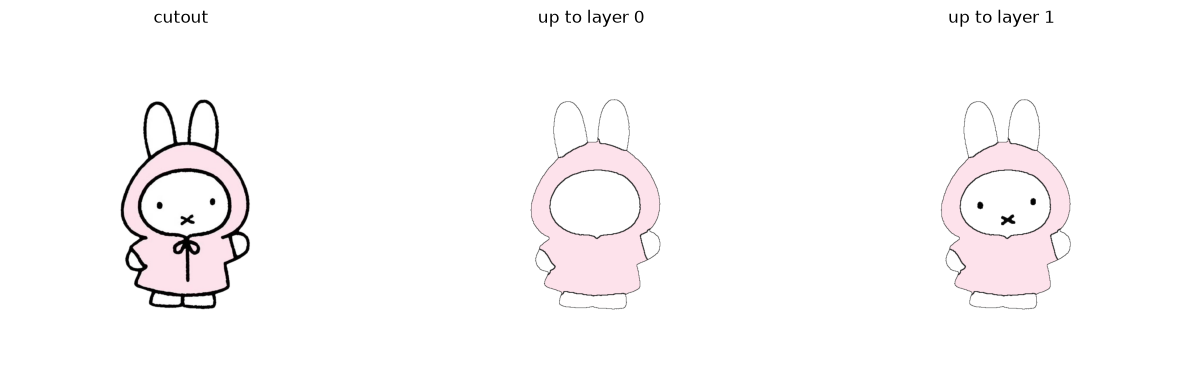

In [12]:
import importlib
import src.segmentation_layers as SL
importlib.reload(SL)

rgba, _ = remove_background(load_rgb(DATA_2D / "medium" / "1m.jpg", 768))
pieces, stitch = SL.segment_layers(rgba)

for p in pieces:
    print(p["id"], "layer", p["layer"], p["kind"], "on", p["parent"], p["color"])

top = max(p["layer"] for p in pieces)
views = [rgba] + [SL.render_layers(pieces, rgba.shape[:2], upto=u) for u in range(top + 1)]
show(views, ["cutout"] + [f"up to layer {u}" for u in range(top + 1)])